In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
import copy
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM'

In [3]:
directory_path = '/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (direc/tories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[202]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values )

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]


Randomly selected eid: /Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2/746d1902-fa59-4cab-b0aa-013be36060d5
cosmos
CB       144
HB      1138
HPF      195
HY       137
TH       796
root     111
dtype: int64


In [7]:
N_NEURONS  = response_matrix_train.shape[3]
data = np.mean(response_matrix_train, axis = 0)
data = (data - np.mean(data, axis=(0, 1),keepdims=True)) / np.std(data,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
data_snr = []
for neuron in range(N_NEURONS):
    means = []
    for t in range(99):
        h = (data[:, t + 1, neuron] - data[:, t , neuron]  ) / (data[:, t, neuron] + 10)
        means.append(np.mean(np.abs(h)))
    data_snr.append(np.mean(means))
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
#data =np.mean(data, axis = 0)

data = data.reshape(-1, data.shape[2])


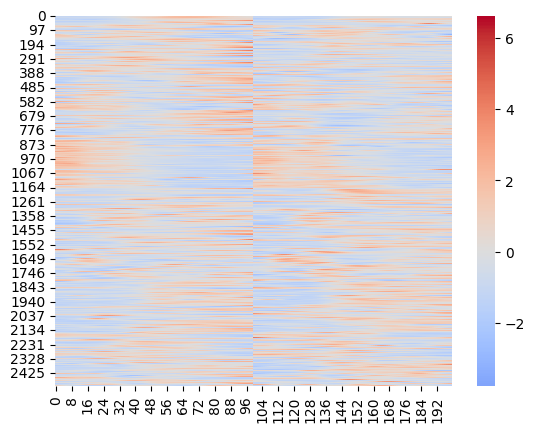

In [8]:
plt.figure()
sns.heatmap(data.T,cmap='coolwarm',center=0)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

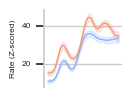

In [344]:
neuron = 4
#neuron = np.argsort( beta.detach()[:rnn.n])[0]
#neuron  = 2
#neuron = np.argsort(snr[:rnn.n])[-2]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_1.jpg',
            format='jpeg',
            dpi=450,

            bbox_inches='tight', transparent=True)

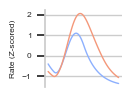

In [327]:



x =rnn.forward(condition_train, steps=100)[:,:,:rnn.n]
#x = rnn.observation_layer(x)
x = (x-torch.mean(x,dim=(0,1), keepdim=True))/torch.std(x,dim=(0,1), keepdim=True)
rows = []
for trial in range(condition_train.shape[0]):
    for t in range(response_matrix_train.shape[2]):
        rows.append({'condition': condition_train[trial,:].item(),
                         'trial': trial,
                         't':t,
                         'x': x[trial, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==-1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [306]:
response_matrix_train.shape

(500, 2, 100, 1253)

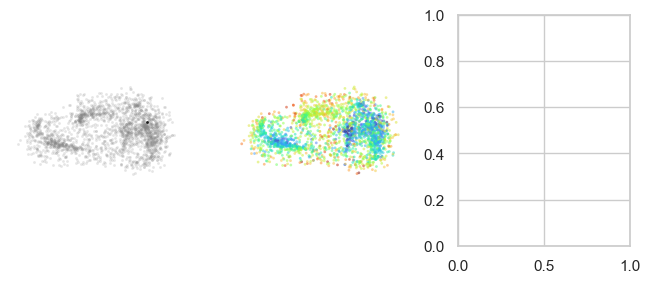

In [415]:
#########################################################################
################ Time series embedding for bwm data  ####################
#########################################################################

fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])

fit = umap.UMAP( densmap=True,dens_lambda=1,n_neighbors = 400)
x_proj= fit.fit_transform(data.T)
#x_proj = projection_model(torch.FloatTensor(data.T)).detach().numpy()


sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .2,color='gray')
sns.scatterplot(x=x_proj[None,4,0], y=x_proj[None,4,1],s=4,ax=ax0,legend = False,lw = 0,alpha = 1,color='k')
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data_snr,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [416]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split



# Convert to PyTorch Tensors
X = torch.FloatTensor(data.T)
y = torch.FloatTensor(x_proj[:,:2])
train_ds = TensorDataset(X, y)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

# 2. Define the Model
class ProjectionNet(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(ProjectionNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            # Linear output layer (no activation for regression)
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.network(x)

# 3. Setup Training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
projection_model = ProjectionNet(X.shape[1], y.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(projection_model.parameters(), lr=0.0001)
#scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5)

# 4. Training Loop
epochs = 2000
for epoch in range(epochs):
    projection_model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = projection_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)


    if epoch % 10 == 0:
        print(f"Epoch [{epoch}/{epochs}], Loss: {avg_loss:.4f}")

# 5. Prediction Function
def project_new_data(new_data):
    projection_model.eval()
    with torch.no_grad():
        # Scale input, pass through model, then inverse scale the result

        output = projection_model(new_data).cpu().numpy()
        return output

Epoch [0/2000], Loss: 195.5091
Epoch [10/2000], Loss: 35.0594
Epoch [20/2000], Loss: 1.0105
Epoch [30/2000], Loss: 0.5309
Epoch [40/2000], Loss: 0.4520
Epoch [50/2000], Loss: 0.4248
Epoch [60/2000], Loss: 0.3777
Epoch [70/2000], Loss: 0.3334
Epoch [80/2000], Loss: 0.3226
Epoch [90/2000], Loss: 0.2847
Epoch [100/2000], Loss: 0.3492
Epoch [110/2000], Loss: 0.2754
Epoch [120/2000], Loss: 0.2592
Epoch [130/2000], Loss: 0.2427
Epoch [140/2000], Loss: 0.2338
Epoch [150/2000], Loss: 0.2411
Epoch [160/2000], Loss: 0.2282
Epoch [170/2000], Loss: 0.1849
Epoch [180/2000], Loss: 0.2018
Epoch [190/2000], Loss: 0.1764
Epoch [200/2000], Loss: 0.1994
Epoch [210/2000], Loss: 0.1672
Epoch [220/2000], Loss: 0.1635
Epoch [230/2000], Loss: 0.1573
Epoch [240/2000], Loss: 0.1596
Epoch [250/2000], Loss: 0.1720
Epoch [260/2000], Loss: 0.1834
Epoch [270/2000], Loss: 0.1586
Epoch [280/2000], Loss: 0.1415
Epoch [290/2000], Loss: 0.1363
Epoch [300/2000], Loss: 0.1302
Epoch [310/2000], Loss: 0.1379
Epoch [320/2000]

KeyboardInterrupt: 

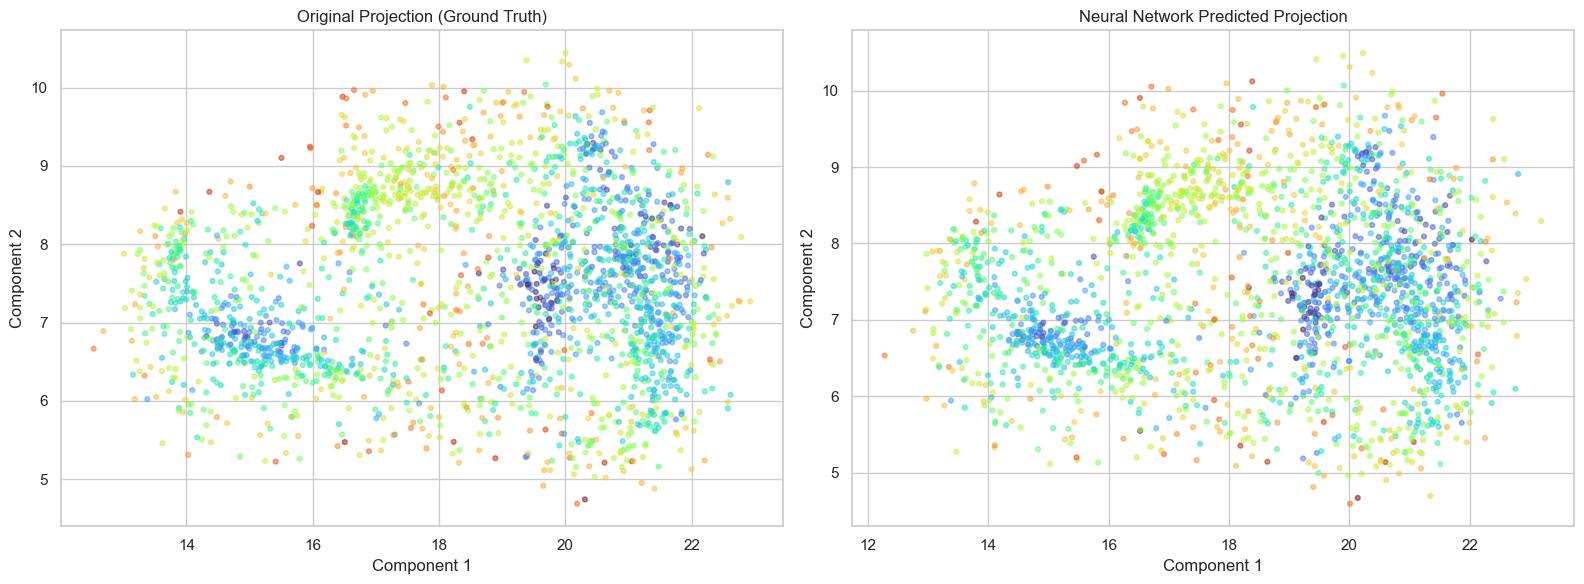

In [417]:
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_results(X_orig, Y_ground_truth, model, device):
    # 1. Get model predictions for the entire dataset
    model.eval()
    with torch.no_grad():
        X_tensor = X_orig
        Y_pred = model(X_tensor).cpu().numpy()


    # 2. Setup the plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Plot Ground Truth
    ax1.scatter(Y_ground_truth[:, 0], Y_ground_truth[:, 1],
                alpha=0.5, s=12, c=data_snr, cmap='turbo')
    ax1.set_title('Original Projection (Ground Truth)')
    ax1.set_xlabel('Component 1')
    ax1.set_ylabel('Component 2')

    # Plot Model Prediction
    ax2.scatter(Y_pred[:, 0], Y_pred[:, 1],
                alpha=0.5, s=12,c=data_snr, cmap='turbo')
    ax2.set_title('Neural Network Predicted Projection')
    ax2.set_xlabel('Component 1')
    ax2.set_ylabel('Component 2')

    plt.tight_layout()
    plt.show()

# Execute visualization
visualize_results(X, y, projection_model,'cpu')

In [6]:
#########################################################################
########################### Fit RNN to data  ############################
#########################################################################

condition_matrix_train = torch.tensor(condition_matrix_train).float()
condition_train = torch.mean(condition_matrix_train,dim = 0)
y_train = torch.tensor(response_matrix_train).float()
y_train = torch.mean(y_train,dim = 0)


y_train = (y_train - torch.mean(y_train, dim=(0, 1),keepdims=True)) / torch.std(y_train,dim=(0, 1),keepdims=True)

rnn = RNN(n = y_train.shape[2], input_dim = 5, n_conditions = condition_train.shape[1],beta=20,sigma_rec=0.)
epochs  = 1000
steps = 100
my_dataset = TensorDataset(y_train,condition_train)  # create your datset
my_dataloader = DataLoader(my_dataset, batch_size=128,shuffle=False)
optimizer = torch.optim.Adam(rnn.parameters(), lr=.001, weight_decay=0.001)

#rnn.recurrent_layer.bias.data[:rnn.n] = torch.FloatTensor(target_mean)

In [58]:

epoch = 0
while epoch < epochs:

    for batch_idx, (y_batch,conditions_batch) in enumerate(my_dataloader):
        optimizer.zero_grad()
        x_batch = rnn.forward(conditions_batch, steps)

        x_batch = x_batch[:,:,:rnn.n]
        reg_loss = 1* torch.std(torch.std(x_batch, dim=[0, 1])) + \
            1 * torch.std(torch.mean(x_batch, dim=[0, 1]))

        center = torch.mean(x_batch,dim = (0,1))
        scale = torch.std(x_batch,dim = (0,1))
        x_batch  = (x_batch - center)/(scale)

       # g = calculate_gain(rnn,conditions_batch,steps,epsilon = 10)

       # x_batch = (x_batch - torch.mean(x_batch, dim=[0, 1])) / (torch.std(x_batch, dim=[0, 1]) + 1e-4)
        eigs = torch.sort(torch.real(
            torch.linalg.eigvals(torch.cov(x_batch.reshape(-1, x_batch.shape[2]).t()))),
                          descending=True)[0]
        fve = eigs/torch.sum(eigs)
        #variance_loss = nn.MSELoss()(fve[:10],fve_target[:10])

        # Compute mean squared error for each neuron normalized by the variance in that neuron
        loss = 1*torch.nn.MSELoss()(y_batch,x_batch) + 0.4*reg_loss
        loss.backward()
        optimizer.step()
        rnn.recurrent_layer.bias.data = torch.nn.ReLU()(rnn.recurrent_layer.bias.data)
        epoch += 1

        if epoch % 10 == 0:

            print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
            print("loss: {:.4f}".format(loss.item()))
            #writer.
            #add_scalar('Loss/test', loss.item(), epoch)

Epoch: 10/1000............. loss: 0.4756
Epoch: 20/1000............. loss: 0.3145
Epoch: 30/1000............. loss: 0.2317
Epoch: 40/1000............. loss: 0.2056
Epoch: 50/1000............. loss: 0.1811
Epoch: 60/1000............. loss: 0.1671


KeyboardInterrupt: 

In [8]:

# Calculate FVE to use as target
x = rnn(condition_train,steps = 100)
y = x.detach().numpy().reshape(-1,x.shape[2])
fve_target = torch.tensor(PCA().fit(y).explained_variance_ratio_).float()

In [59]:

def calculate_gain(rnn,conditions,steps,epsilon):
        # Simulate RNN
        x = rnn.forward(conditions,steps)
        # Z-score
        x = (x - torch.mean(x, dim=(0, 1))) / torch.std(x,dim=(0, 1))
        h = torch.abs(torch.diff(x,dim=1)/(x[:,:-1,:]+epsilon))
        g = torch.mean(h,dim=(0,1))
        return g

In [124]:
import torch

def compute_ratio_with_A(y, A, dt=1.0, epsilon=.00001):
    """
    Computes dot_yi / dot_hi using the recurrent matrix A.

    Args:
        y: Tensor of shape (trials, time, neurons)
        A: Recurrent weight matrix (neurons, neurons)
        dt: Time step
        epsilon: Stability constant to handle "stalling" (small dot_y)

    Returns:
        ratio: dot_y / dot_h (trials, time, neurons)
    """
    # 1. Compute dot_y for all neurons
    # dot_y shape: (trials, time, neurons)
    dot_y = torch.gradient(y, spacing=dt, dim=1)[0]

    # 2. Compute dot_h using the structure: dot_h = A @ dot_y
    # We need to rearrange dot_y to (trials, neurons, time) for matrix mult
    # or use einsum for clarity.
    # 'tn' is trial/neuron, 'ij' is matrix A, 'tj' is trial/neighbor neuron
    # We want: dot_h[trial, time, i] = sum_j A[i, j] * dot_y[trial, time, j]
    dot_h = torch.einsum('ij, btj -> bti', A, dot_y)

    # 3. Calculate the ratio dot_y / dot_h
    # We apply the epsilon to the denominator to handle regions where
    # the network input is static (dot_h approx 0).
    ratio = dot_y / (dot_h + torch.sign(dot_h) * epsilon)

    return ratio, dot_h, dot_y

# Usage:
# ratio, dh, dy = compute_ratio_with_A(y_tensor, A_matrix)

In [147]:
import torch
import torch.nn.functional as F

def compute_local_regression(X, Y, window_size=5):
    """
    Computes a local regression coefficient beta for each neuron/time/trial.
    X, Y: Tensors of shape (trials, ntime, nneurons)
    window_size: Odd integer for the temporal window
    """
    ntrials, ntime, nneurons = X.shape
    padding = window_size // 2

    # 1. Pad the time dimension to maintain the same ntime output
    # Padding only the 'time' dimension (dim 1)
    X_padded = F.pad(X.transpose(1, 2), (padding, padding), mode='replicate').transpose(1, 2)
    Y_padded = F.pad(Y.transpose(1, 2), (padding, padding), mode='replicate').transpose(1, 2)

    # 2. Extract windows using unfold
    # Resulting shape: (trials, ntime, nneurons, window_size)
    X_windows = X_padded.unfold(1, window_size, 1)
    Y_windows = Y_padded.unfold(1, window_size, 1)

    # 3. Solve for Beta (Simple Linear Regression: Beta = cov(X,Y) / var(X))
    # We compute this for each neuron at each timepoint across the window

    # Center the data within each window (Local Mean Subtraction)
    X_mean = X_windows.mean(dim=-1, keepdim=True)
    Y_mean = Y_windows.mean(dim=-1, keepdim=True)

    X_centered = X_windows - X_mean
    Y_centered = Y_windows - Y_mean

    # Sum of products and Sum of squares over the window dimension (-1)
    num = (X_centered * Y_centered).sum(dim=-1)
    den = (X_centered**2).sum(dim=-1)

    # 4. Compute Beta
    # Add epsilon to denominator to handle zero-variance windows
    beta = num / (den + 1e-6)

    return beta

# Example usage:
# beta = compute_local_regression(y_tensor, h_tensor, window_size=7)

In [150]:
y = rnn(condition_train,100)
h = rnn.recurrent_layer(y)
ydot = -y + rnn.activation(h)
g = compute_local_regression(y, h, window_size=5)
g  = torch.mean(torch.abs(g), dim=(0,1)).detach().numpy()
#g = torch.mean(y,dim=(0,1)).detach()
g = torch.mean(torch.abs(ydot), dim =(0,1)).detach()
#
# g, dh, dy = compute_ratio_with_A(y, rnn.recurrent_layer.weight.data)
# g =torch.mean(g,dim=(0,1)).detach()

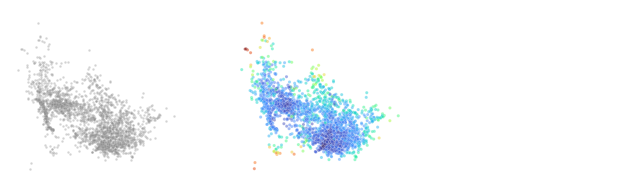

In [151]:
####################################################################
#################### DensMap plot for fit RNN ######################
####################################################################

from sklearn.manifold import TSNE
#g = calculate_gain(rnn,condition_train,100,10).detach()
#conditions = torch.FloatTensor(np.linspace(-1,1,100))[:,None]
#rnn.alpha = .05
x = rnn(condition_train,100).detach()

#x = rnn(condition_train,100).detach()
x = x[:,:,:rnn.n]
#x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))

x = x.detach().numpy()
#g =  calculate_gain(rnn,conditions,200,1).detach()



#fit = umap.UMAP(n_components = 2,densmap = True, dens_lambda =1 ,n_neighbors = 400)
#x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()
#pca = PCA(n_components=2).fit(x.reshape(-1,x.shape[2]).T)
#x_proj = pca.transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')

for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


In [36]:
g.max()

np.float32(2.9500697)

In [45]:
# Plot curvature
print("Simulating RNN...")
rnn.alpha = .025
x = rnn(torch.FloatTensor(np.linspace(-1,1,100))[:,None],200).detach()
#x = (x-torch.mean(x,d

print("Fitting PCA...")
pca = PCA().fit(x.reshape(-1,x.shape[2]))

Simulating RNN...
Fitting PCA...


In [125]:
print("Creating dataframe...")
rows = []
x = torch.tensor(x).float()
x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
h = rnn.recurrent_layer(x)
flow_field = -x + rnn.activation(h)
e = torch.exp(torch.clamp(1*h,-20,20))
b=1*e/(1+e)**2
#b = stable_sigmoid_derivative(beta*h)
w_rec =  rnn.recurrent_layer.weight.data.detach()
curvature =  rnn.beta*(flow_field.detach() @ w_rec.t())**2 * b

Creating dataframe...


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_15107/2964205753.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x).float()


In [126]:
rows = []
for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    for t in range(x.shape[1]):
        rows.append({'t': t,
             'trial': trial,
             'x': proj_trajectory[t,0],
             'y': proj_trajectory[t,1],
             'z': proj_trajectory[t,2],
            'b': torch.linalg.norm(b[trial,t,2]).item(),
             'c': torch.linalg.norm(curvature[trial,t,np.argsort(g)[2]]).item()
                     })

new_df = pd.DataFrame(rows)
x.shape

torch.Size([100, 200, 2068])

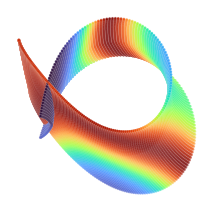

In [127]:
fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax=fig.add_subplot(gs[0,0])

sns.scatterplot(data = new_df, x = 'y', y = 'z', hue = 'b',palette = 'turbo',s=4,legend=False,alpha = .5,ax=ax,lw=.1)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_boundary_8.jpg',
        format='jpeg',
        dpi=450,
        bbox_inches='tight', transparent=True)
# ax.spines['left'].set_color('black')
# ax.spines['bottom'].set_color('black')


In [419]:
# Get indices of lowest gains
g_restr = g[:rnn.n]


q1_val = np.quantile(g_restr, 0.25) # 25th percentile value
# Get original indices for all elements <= q1
indices = [i for i, x in enumerate(g_restr) if x <= q1_val]
print(indices)
complement_indices = [i for i, x in enumerate(g_restr) if x > q1_val]
# Alternative using set operations:
# complement_indices = list(set(range(len(data))) - set(q1_indices))



[11, 12, 15, 16, 28, 40, 44, 46, 47, 55, 58, 63, 69, 71, 75, 80, 88, 89, 93, 95, 98, 99, 102, 103, 109, 111, 119, 130, 133, 135, 137, 138, 146, 150, 154, 155, 157, 158, 159, 161, 167, 174, 177, 180, 181, 182, 184, 186, 189, 191, 198, 200, 203, 204, 205, 206, 207, 211, 212, 213, 214, 215, 216, 219, 220, 223, 225, 228, 229, 230, 241, 243, 245, 248, 249, 252, 253, 256, 259, 261, 262, 263, 264, 267, 268, 269, 271, 272, 273, 274, 285, 286, 289, 290, 291, 294, 295, 296, 300, 301, 302, 306, 312, 314, 315, 316, 317, 318, 320, 323, 324, 332, 333, 334, 336, 337, 339, 342, 346, 350, 351, 357, 358, 360, 363, 364, 367, 368, 370, 374, 377, 379, 380, 382, 384, 385, 386, 388, 389, 390, 392, 394, 395, 396, 400, 402, 403, 410, 414, 418, 419, 421, 422, 427, 428, 431, 434, 435, 437, 441, 442, 444, 446, 451, 453, 454, 455, 460, 462, 466, 468, 469, 470, 473, 475, 476, 477, 478, 479, 481, 482, 483, 484, 485, 486, 487, 490, 495, 497, 498, 501, 512, 515, 516, 518, 519, 526, 527, 528, 532, 533, 539, 544, 545, 5

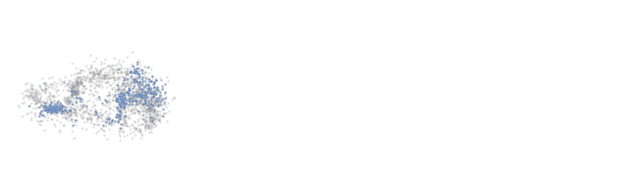

In [420]:
####################################################################
#################### Highlight low gain neurons ######################
####################################################################

fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .25,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[indices,0],y = x_proj[indices,1],s=3,ax=ax0,alpha = .5,legend = False)

#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =mag[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


In [498]:
perturbed_rnn = copy.deepcopy(rnn)
condition_matrix_train = torch.tensor(condition_matrix_train).float()
condition_train = torch.mean(condition_matrix_train,dim = 0)
y_train = torch.tensor(response_matrix_train).float()
y_train = torch.mean(y_train,dim = 0)


y_train = (y_train - torch.mean(y_train, dim=(0, 1),keepdims=True)) / torch.std(y_train,dim=(0, 1),keepdims=True)
my_dataset = TensorDataset(y_train,condition_train)  # create your datset
my_dataloader = DataLoader(my_dataset, batch_size=128,shuffle=False)
optimizer = torch.optim.Adam(perturbed_rnn.parameters(), lr=.0002, weight_decay=0)


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_15107/61620250.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  condition_matrix_train = torch.tensor(condition_matrix_train).float()


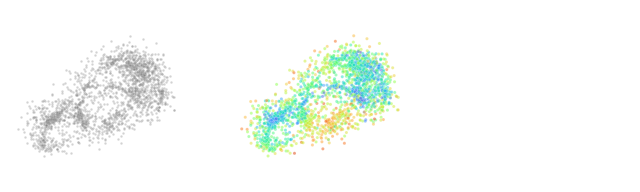

In [371]:
  ;####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
#perturbed_rnn = copy.deepcopy(rnn)
from sklearn.manifold import TSNE


g = calculate_gain(perturbed_rnn,condition_train,100,10).detach()


x = perturbed_rnn(condition_train,100).detach()

x = x[:,:,:rnn.n]

x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
#x = x  + 2*(2*torch.rand_like(x)-1)

x = x.detach().numpy()
#x_proj  = PCA(n_components = 2).fit_transform(responses.T)
#x_proj  = TSNE(n_components = 2,perplexity = 800).fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(x.reshape(-1,x.shape[2]).T)
# fit = umap.UMAP(n_components = 2,densmap=True,dens_lambda =10)
# fit = umap.UMAP(n_components = 2,densmap=True,dens_lambda =2,n_neighbors =200)
x_proj= fit.transform(x.reshape(-1,x.shape[2]).T)
#x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()

fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo',hue_norm = (0.0008,.015))

#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =mag[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


Generating Seaborn frames...
Epoch: 0/500............. gain_loss: 0.0063 var_1: 0.2744 var_2: 0.1074
Epoch: 1/500............. gain_loss: 0.0054 var_1: 0.1671 var_2: 0.1058
Epoch: 2/500............. gain_loss: 0.0049 var_1: 0.1090 var_2: 0.1066
Epoch: 3/500............. gain_loss: 0.0046 var_1: 0.0810 var_2: 0.1101
Epoch: 4/500............. gain_loss: 0.0044 var_1: 0.0669 var_2: 0.1097
Epoch: 5/500............. gain_loss: 0.0042 var_1: 0.0572 var_2: 0.1114
Epoch: 6/500............. gain_loss: 0.0041 var_1: 0.0506 var_2: 0.1116
Epoch: 7/500............. gain_loss: 0.0041 var_1: 0.0448 var_2: 0.1080
Epoch: 8/500............. gain_loss: 0.0040 var_1: 0.0404 var_2: 0.1089
Epoch: 9/500............. gain_loss: 0.0040 var_1: 0.0364 var_2: 0.1120
Epoch: 10/500............. gain_loss: 0.0040 var_1: 0.0334 var_2: 0.1138
Epoch: 11/500............. gain_loss: 0.0040 var_1: 0.0309 var_2: 0.1171
Epoch: 12/500............. gain_loss: 0.0040 var_1: 0.0287 var_2: 0.1185
Epoch: 13/500............. gain_

KeyboardInterrupt: 

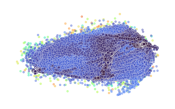

In [499]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Setup the figure and styling
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(2,2))

# Define constant axis limits so the video doesn't "jump"
# ax.set_xlim(0, 10)
# ax.set_ylim(-2, 2)

frames = []
n_points = 50

g = calculate_gain(perturbed_rnn,condition_train,100,10).detach()
x = perturbed_rnn(condition_train,100).detach()
x = x[:,:,:rnn.n]
x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
x = x.detach().numpy()
x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()
#x_proj= fit.transform(x.reshape(-1,x.shape[2]).T)
# Generate the scatterplot
# We pass the ax to ensure everything stays on the same figure
scatter=sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax,s=3,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo',hue_norm = (0.0008,.015))
# IMPORTANT: sns.scatterplot returns an Axes object,
# but ArtistAnimation needs the 'collections' (the dots)
# We grab the last collection added to the axes
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_aspect('equal')
frames.append([ax.collections[-1]])

print("Generating Seaborn frames...")
epochs  = 500
# 2. Animation Loop
for i in range(epochs):

    # Create synthetic moving data
    for batch_idx, (y_batch,conditions_batch) in enumerate(my_dataloader):
        optimizer.zero_grad()
        x_batch = perturbed_rnn.forward(conditions_batch, steps)[:,:,:rnn.n]
        y_batch = rnn.forward(conditions_batch, steps).detach()[:,:,:rnn.n]
        activity_loss = nn.MSELoss()(x_batch[:,:,indices],y_batch[:,:,indices])

        g = calculate_gain(perturbed_rnn,conditions_batch,steps,epsilon = 10)
        #gain_loss  = torch.mean(g[g>q1_val])
        gain_loss= torch.mean(g)

        #
        x_batch = (x_batch - torch.mean(x_batch, dim=[0, 1])) / (torch.std(x_batch, dim=[0, 1]) + 1e-4)
        eigs = torch.sort(torch.real(
            torch.linalg.eigvals(torch.cov(x_batch.reshape(-1, x_batch.shape[2]).t()))),
                          descending=True)[0]
        fve = eigs/torch.sum(eigs)
        variance_loss = nn.MSELoss()(fve[:10],fve_target[:10])
        variance_loss_1 = torch.sum(fve[4:])
        variance_loss_2 = (fve[3] - .25)**2
        reg_loss = 1* torch.std(torch.std(x_batch, dim=[0, 1])) + \
                    1 * torch.std(torch.mean(x_batch, dim=[0, 1]))
        loss = 30*gain_loss + 1*variance_loss_1 + 2*variance_loss_2+ .4 *reg_loss
        #loss = gain_loss + torch.sum(fve[4:])
       # loss = -gain_loss #+ 1*variance_loss+.01*torch.mean((torch.mean(x_batch,dim=(0,1)) -rate_target_mean)**2)
        # Compute mean squared error for each neuron normalized by the variance in that neuron

        loss.backward()
        optimizer.step()
        #self.recurrent_layer.bias.data = torch.nn.ReLU()(self.recurrent_layer.bias.data)
        #self.alpha.data = torch.nn.Softplus()(self.alpha.data)
        epoch += 1

    print('Epoch: {}/{}.............'.format(i, epochs), end=' ')
    print("gain_loss: {:.4f}".format(gain_loss.item()), end=' ')
    print("var_1: {:.4f}".format(variance_loss_1.item()), end=' ')
    print("var_2: {:.4f}".format(fve[3].item()))

    g = calculate_gain(perturbed_rnn,condition_train,100,10).detach()
    x = perturbed_rnn(condition_train,100).detach()
    x = x[:,:,:rnn.n]
    x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
    x = x.detach().numpy()
    x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()
    #x_proj= fit.transform(x.reshape(-1,x.shape[2]).T)
    # Generate the scatterplot
    # We pass the ax to ensure everything stays on the same figure
    scatter=sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax,s=3,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo',hue_norm = (0.0008,.05))
    # IMPORTANT: sns.scatterplot returns an Axes object,
    # but ArtistAnimation needs the 'collections' (the dots)
    # We grab the last collection added to the axes
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
    frames.append([ax.collections[-1]])

# 3. Create and Save
ani = animation.ArtistAnimation(fig, frames, interval=50, blit=True)

output_file = "seaborn_scatter.mp4"
print(f"Saving to {output_file}...")

try:
    # Using 30fps for smoother motion
    ani.save(output_file, writer='ffmpeg', fps=30)
    print("Done!")
except Exception as e:
    print(f"Error: {e}")

plt.close()

In [405]:
fve[4:10]

tensor([0.0016, 0.0008, 0.0005, 0.0003, 0.0002, 0.0002],
       grad_fn=<SliceBackward0>)

In [406]:
fve[0:10]

tensor([3.1118e-01, 2.3148e-01, 2.2750e-01, 2.2579e-01, 1.5536e-03, 8.4048e-04,
        4.6125e-04, 2.9665e-04, 2.4495e-04, 2.1794e-04],
       grad_fn=<SliceBackward0>)

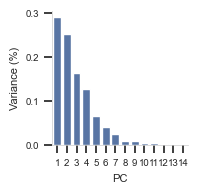

In [492]:
x = rnn(condition_train,100).detach()
pca = PCA().fit(x.reshape(-1,x.shape[2]).detach())
fig = plt.figure(figsize=(1.75,1.75))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])

sns.barplot(x = np.arange(1,15),y = pca.explained_variance_ratio_[:14],ax=ax)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
# from scipy import stats
# res1 = stats.pearsonr(snr[:rnn.n], beta.detach()[:rnn.n])
# ax2.set_xlabel("g",fontsize=7)
# ax2.set_ylabel("Noise (model)",fontsize=7)
# ax2.set_title(str(res1[0]),fontsize=7)
# ax1.set_xlabel("Noise",fontsize=7)
ax.set_xlabel("PC",fontsize=8)
ax.set_ylabel("Variance (%)",fontsize=8)
# ax0.set_ylabel("Count",fontsize=7)
# ax1.set_ylabel("Count",fontsize=7)
plt.savefig('Figures/Figure_boundary_8.jpg',
        format='jpeg',
        dpi=450,
        bbox_inches='tight', transparent=True)

f

In [500]:
# 3. Create and Save
ani = animation.ArtistAnimation(fig, frames, interval=50, blit=True)

output_file = "seaborn_scatter.mp4"
print(f"Saving to {output_file}...")

try:
    # Using 30fps for smoother motion
    ani.save(output_file, writer='ffmpeg', fps=30)
    print("Done!")
except Exception as e:
    print(f"Error: {e}")

plt.close()

Saving to seaborn_scatter.mp4...
Done!


In [382]:
variance_loss_1

tensor(3.8392e-05, grad_fn=<SumBackward0>)

In [166]:
ani = animation.ArtistAnimation(fig, frames, interval=50, blit=True)

output_file = "seaborn_scatter.mp4"
print(f"Saving to {output_file}...")

try:
    # Using 30fps for smoother motion
    ani.save(output_file, writer='ffmpeg', fps=30)
    print("Done!")
except Exception as e:
    print(f"Error: {e}")

plt.close()

Saving to seaborn_scatter.mp4...
Done!


In [156]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM'

In [1082]:
g = calculate_gain(rnn,torch.FloatTensor(np.linspace(-1,1,100))[:,None],100,.1).detach()
np.argsort(g)[0]

tensor(1359)

In [1083]:
print("Simulating RNN...")
rnn.alpha = .025
x = perturbed_rnn(torch.FloatTensor(np.linspace(-1,1,100))[:,None],200).detach()
#x = (x-torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
x = x.detach().numpy()

print("Fitting PCA...")
pca = PCA().fit(x.reshape(-1,x.shape[2]))

Simulating RNN...
Fitting PCA...


In [1084]:
# Plot curvature
##########################################
########## Plotting manifolds ############
##########################################


#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))


def stable_sigmoid_derivative(x):
    # Use e^x form for negative numbers, e^-x form for positive numbers
    return torch.where(x >= 0,
                    torch.exp(-x) / (1 + torch.exp(-x))**2,
                    torch.exp(x) / (1 + torch.exp(x))**2)

print("Creating dataframe...")
rows = []
x = torch.tensor(x).float()
#x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))

h = perturbed_rnn.recurrent_layer(x)

flow_field = -x + perturbed_rnn.activation(h)

e = torch.exp(torch.clamp(20*h,-20,20))
b=20*e/(1+e)**2
#b = stable_sigmoid_derivative(beta*h)
w_rec =  perturbed_rnn.recurrent_layer.weight.data.detach()
curvature =  perturbed_rnn.beta*(flow_field.detach() @ w_rec.t())**2 * b


Creating dataframe...


In [1096]:
rows = []
for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    for t in range(x.shape[1]):
        rows.append({'t': t,
             'trial': trial,
             'x': proj_trajectory[t,0],
             'y': proj_trajectory[t,1],
             'z': proj_trajectory[t,2],
            'b': torch.linalg.norm(b[trial,t,np.argsort(g)[-22]]).item(),
             'c': torch.linalg.norm(curvature[trial,t,np.argsort(g)[0]]).item()
                     })

new_df = pd.DataFrame(rows)
x.shape

torch.Size([100, 200, 2068])

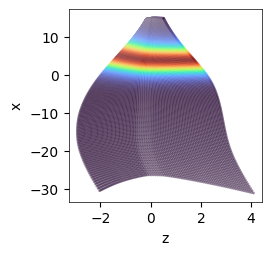

In [1097]:
fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax0=fig.add_subplot(gs[0,0])

vmin = 0
vmax = .25
sns.scatterplot(data = new_df, x = 'z', y = 'x', hue = 'b',palette = 'turbo',s=4,legend=False,alpha = .5,ax=ax0,lw=.1)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_boundary_8.jpg',
        format='jpeg',
        dpi=450,
        bbox_inches='tight', transparent=True)
# ax.spines['left'].set_color('black')
# ax.spines['bottom'].set_color('black')


In [981]:
new_df.c.max()

1748.7388916015625

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42592/3840680103.py:12: UserWarning:

To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).



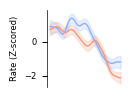

In [695]:
neuron = np.argsort(g)[0]
#############################################################
############### PSTH ########################################
#############################################################


############### ******** ############
response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                         keepdims=True)) / np.std(response_matrix_train,
                                                                                  axis=(0, 1, 2),
                                                                                  keepdims=True)
condition_matrix_train = torch.tensor(condition_matrix_train).float()
y_train = torch.tensor(y_train).float()
y_train = response_matrix_train.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
condition_train = condition_matrix_train.reshape(-1,condition_matrix_train.shape[2])


#neuron = np.argsort( beta.detach()[:rnn.n])[0]
#neuron  = 2
#neuron = np.argsort(snr[:rnn.n])[-2]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [635]:
neuron = [np.argsort(g)[1300]]

In [24]:
new_df.c.max()

1338.563720703125

In [59]:
np.argsort(g)[1300]

tensor(1863)

<Axes: xlabel='None', ylabel='Count'>

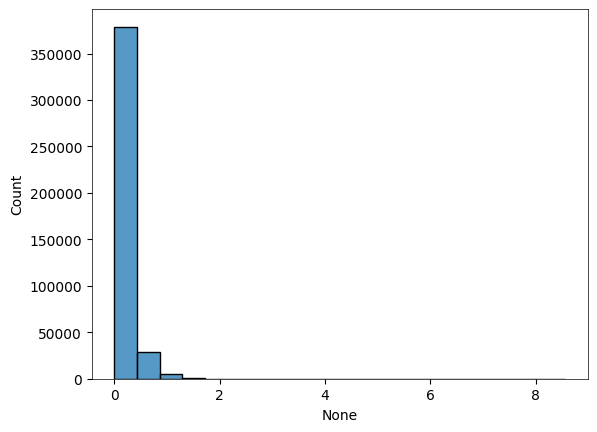

In [97]:
# Distribution of h/y
y = rnn.forward(condition_train,steps)


f = perturbed_rnn.activation(perturbed_rnn.recurrent_layer(y))

ratio = (f/(y+100)).detach().flatten()
plt.figure()
sns.histplot(x = ratio.flatten().detach())



<Axes: xlabel='None', ylabel='Count'>

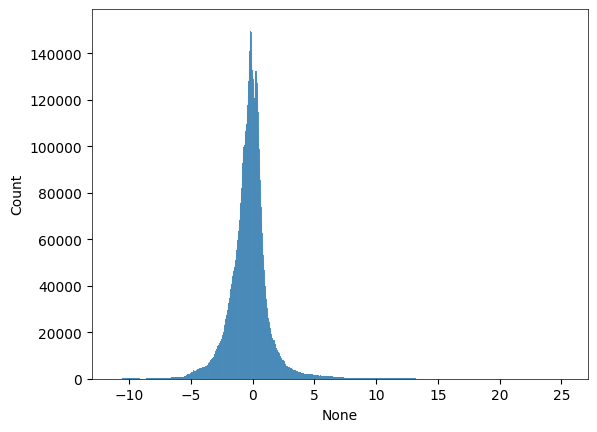

In [175]:
plt.figure()
sns.histplot(x = h.flatten().detach())

<Axes: xlabel='None', ylabel='Count'>

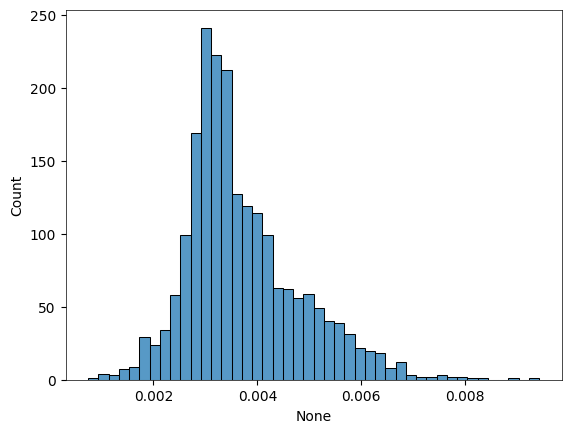

In [233]:
plt.figure()
sns.histplot(x = g)

<Axes: ylabel='Count'>

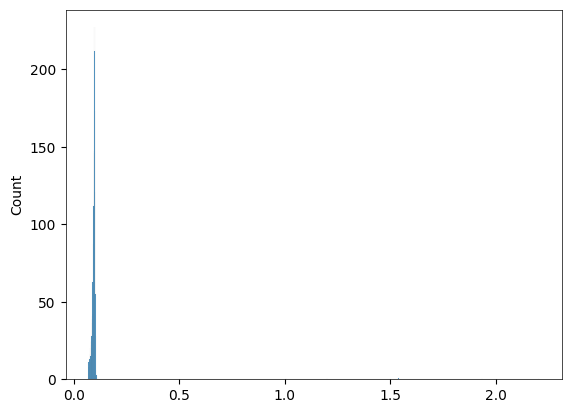

In [898]:
x = perturbed_rnn(torch.FloatTensor(np.linspace(-1,1,50))[:,None],100).detach()

x = x.detach().numpy()
plt.figure()
sns.histplot(x= np.std(x,axis = (0,1)))